# 03b – Phân loại Pass/Fail theo chi phí giả định

**Mục tiêu:** so sánh Logistic Regression (LR) và Random Forest (RF), chọn tham số và ngưỡng để giảm chi phí kỳ vọng của quyết định phân loại.

- **Phạm vi:** phân loại sản phẩm từ 590 phép đo; timestamp không nằm trong đầu vào mô hình.
- **Kết quả modeling hiện tại:** là số đo thực nghiệm đã có, được giữ làm baseline. Chỉ **chi phí** trong notebook này là giả định, không đổi nhãn hoặc biến kết quả cũ thành số giả lập.
- **Input:** dữ liệu SECOM, cách chia train/test hiện có và các bảng baseline đã lưu.
- **Output riêng:** `artifacts/cost_sensitive/` và `figures/cost_sensitive/`. Không ghi đè `model_final.joblib`, `decision_config.json` hoặc các bảng kết quả cũ.
- **Tập dùng để phát triển:** train 1.253 mẫu, 83 Fail. Holdout 314 mẫu không được dùng chọn tham số, ngưỡng hay tính kết quả mới trong notebook này.

Notebook này là thử nghiệm bổ sung; nó không tự thay thế mô hình đang được dashboard sử dụng.

## 1. Chuyển mục tiêu doanh nghiệp thành ma trận chi phí

Quy ước: **1 = Fail**, **0 = Pass**. FP là sản phẩm tốt bị gán Fail; FN là sản phẩm lỗi bị gán Pass.

Với chi phí không âm cho bốn kết quả, chi phí trung bình trên một sản phẩm được ước lượng bằng:

\[
EC = \frac{C_{TN}TN+C_{FP}FP+C_{FN}FN+C_{TP}TP}{N}.
\]

Chi phí tổng là tử số; chi phí trên 1.000 sản phẩm bằng `EC × 1000`. Đây là **đơn vị chi phí tương đối**, không phải phần trăm lỗi hay số tiền tiết kiệm.

Hai họ kịch bản được phân tích riêng:

| Kết quả | EMC chỉ tính sai phân loại | Kiểm tra mọi sản phẩm được gán Fail — kịch bản chính |
|---|---:|---:|
| TN: Pass → Pass | 0 | 0 |
| FP: Pass → Fail | 1 | 1 |
| FN: Fail → Pass | r | r |
| TP: Fail → Fail | 0 | 1 |

Trong kịch bản chính, kỹ sư kiểm tra cả TP và FP, nên:

\[
EC_{review} = \frac{TP+FP+r\,FN}{N}.
\]

`r = 5, 10, 20` chỉ là các tỷ lệ để khảo sát: bỏ sót một Fail được giả định tốn gấp r lần kiểm tra một sản phẩm. Không coi các tỷ lệ này là số liệu doanh nghiệp hoặc chuẩn ngành.

**Giả định vận hành:** kiểm tra lại phát hiện được lỗi; chi phí bỏ sót là tổn thất kỳ vọng còn lại khi bỏ sót ở bước này, có xét quy trình kiểm soát chất lượng tiếp theo. FN không tự động đồng nghĩa với sản phẩm lỗi đã giao cho khách hàng. Chưa áp đặt Recall tối thiểu vì doanh nghiệp chưa cung cấp yêu cầu đó.

## 2. Cách đánh giá để tránh chọn và chấm điểm trên cùng dữ liệu

Mỗi kịch bản có một phép chọn riêng:

1. **CV ngoài, 5 fold:** giữ một fold làm đánh giá; chỉ các mẫu còn lại được dùng để chọn cấu hình.
2. **CV trong, 3 fold:** tạo dự đoán OOF cho mỗi cấu hình; quét ngưỡng và chọn chi phí thấp nhất. Tiền xử lý và chọn đặc trưng đều được fit lại trong từng fold train.
3. Fit cấu hình đã chọn trên toàn bộ phần train của vòng ngoài, rồi dự đoán fold đánh giá đúng một lần.

Ba quy trình học được báo cáo: LR được tinh chỉnh riêng, RF được tinh chỉnh riêng và **`cost_selected`** (vòng trong chọn cả LR/RF, tham số và ngưỡng). Hai mốc không học là **luôn Pass** và **kiểm tra tất cả**.

Điểm tổng hợp đến từ dự đoán của các fold ngoài. Độ lệch chuẩn chi phí giữa 5 fold chỉ mô tả dao động, **không phải khoảng tin cậy**. Khi quét nhiều cấu hình, điểm tốt nhất ở vòng trong có thể lạc quan; không dùng điểm đó thay kết quả vòng ngoài.

Tài liệu: [scikit-learn: chọn ngưỡng theo chi phí](https://scikit-learn.org/stable/auto_examples/model_selection/plot_cost_sensitive_learning.html), [nested cross-validation](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html).

In [1]:
import json
import sys
import time
from dataclasses import asdict
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Hỗ trợ kernel bắt đầu ở thư mục dự án hoặc một thư mục con của dự án.
project_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (path for path in project_candidates
     if (path / "secom_utils.py").is_file()
     and (path / "secom_preprocessing.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Hãy chạy notebook từ thư mục dự án SECOM hoặc thư mục con của nó.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from secom_utils import SEED, load_secom, get_split
from secom_cost_sensitive import (
    CostScenario,
    make_candidate_specs,
    run_nested_cost_cv,
    fit_final_cost_policies,
    save_final_cost_policies,
)

OUTPUT_DIR = PROJECT_ROOT / "artifacts" / "cost_sensitive"
FIGURE_DIR = PROJECT_ROOT / "figures" / "cost_sensitive"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

OUTER_SPLITS = 5
INNER_SPLITS = 3
FINAL_SPLITS = 5
INCLUDE_ERROR_ONLY_SCENARIOS = True

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 80)
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 120})
print("Project:", PROJECT_ROOT)
print("Python:", sys.executable)
print("SEED:", SEED)
print("Kết quả mới:", OUTPUT_DIR)

Project: D:\AI_Bussiness_Huflit\Đồ án cuối
Python: C:\Users\ductr\AppData\Local\Programs\Python\Python311\python.exe
SEED: 42
Kết quả mới: D:\AI_Bussiness_Huflit\Đồ án cuối\artifacts\cost_sensitive


## 3. Nạp dữ liệu và giữ nguyên holdout

Dùng đúng `load_secom` và `get_split` của dự án. Chỉ truyền các dòng train và 590 cột số vào thí nghiệm. Timestamp được nạp để giữ API của dự án nhưng không truyền vào pipeline.

Notebook không dự đoán hoặc chấm điểm lại holdout. Tập holdout hiện có đã từng được xem trong modeling/evaluation; các thử nghiệm mới cần được xác nhận bằng dữ liệu giữ riêng mới nếu muốn đưa ra kết luận triển khai.

In [2]:
X_raw, y_raw, _timestamp = load_secom()
train_idx, holdout_idx = get_split(y_raw)
X_train = X_raw.iloc[train_idx].copy()
y_train = y_raw.iloc[train_idx].copy()

assert X_train.shape[1] == 590
assert X_train.index.equals(y_train.index)
assert set(train_idx).isdisjoint(set(holdout_idx))
assert X_train.shape[0] == 1253 and int(y_train.sum()) == 83
assert len(holdout_idx) == 314

display(pd.DataFrame({
    "Số mẫu train": [len(y_train)],
    "Pass train": [int((y_train == 0).sum())],
    "Fail train": [int((y_train == 1).sum())],
    "Tỷ lệ Fail train": [float(y_train.mean())],
    "Số cột đầu vào": [X_train.shape[1]],
    "Số mẫu holdout giữ ngoài thí nghiệm": [len(holdout_idx)],
}))

,Số mẫu train,Pass train,Fail train,Tỷ lệ Fail train,Số cột đầu vào,Số mẫu holdout giữ ngoài thí nghiệm
0,1253,1170,83,0.066241,590,314


## 4. Baseline modeling hiện tại — kết quả đã đo

Các bảng dưới đây chỉ đọc lại kết quả cũ. Mô hình cũ được chọn theo AP và ngưỡng theo F1; chưa được chọn theo ma trận chi phí trong notebook mới. Vì cách chọn và cách đánh giá khác nhau, không coi chênh lệch giữa bảng cũ và nested CV mới là mức cải thiện đã được kiểm chứng.

In [3]:
baseline_dir = PROJECT_ROOT / "artifacts" / "results"
baseline_cv_path = baseline_dir / "cv_model_comparison.csv"
if baseline_cv_path.is_file():
    print("Baseline cũ: CV, nhãn tại ngưỡng 0,5; lựa chọn mô hình theo AP.")
    display(pd.read_csv(baseline_cv_path))
else:
    print("Chưa có bảng CV baseline; có thể chạy notebook 03 để bổ sung.")

for model_name, filename in [
    ("RF", "threshold_oof.csv"),
    ("LR", "threshold_oof_lr.csv"),
]:
    source_path = baseline_dir / filename
    if source_path.is_file():
        old_thresholds = pd.read_csv(source_path)
        chosen_mask = old_thresholds["duoc_chon"].astype(str).str.lower().eq("true")
        print(f"{model_name}: ngưỡng cũ chọn bằng F1 trên OOF, không phải chi phí.")
        display(old_thresholds.loc[chosen_mask, [
            "threshold", "precision", "recall", "f1", "balanced_accuracy", "ber",
            "tp", "fp", "fn", "tn", "alarm_rate",
        ]])

Baseline cũ: CV, nhãn tại ngưỡng 0,5; lựa chọn mô hình theo AP.


,Mô hình,AP_mean,AP_std,Recall_Fail_mean,Recall_Fail_std,Precision_Fail_mean,Precision_Fail_std,F1_Fail_mean,F1_Fail_std,Balanced_Accuracy_mean,Balanced_Accuracy_std,BER_mean,BER_std
0,Logistic Regression (balanced),0.163142,0.028963,0.458088,0.060794,0.124581,0.021255,0.195613,0.031109,0.61366,0.035906,0.38634,0.035906
1,Random Forest (balanced),0.203827,0.070119,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.50000,0.000000,0.50000,0.000000


RF: ngưỡng cũ chọn bằng F1 trên OOF, không phải chi phí.


,threshold,precision,recall,f1,balanced_accuracy,ber,tp,fp,fn,tn,alarm_rate
28,0.14,0.186567,0.301205,0.230415,0.604021,0.395979,25,109,58,1061,0.106943


LR: ngưỡng cũ chọn bằng F1 trên OOF, không phải chi phí.


,threshold,precision,recall,f1,balanced_accuracy,ber,tp,fp,fn,tn,alarm_rate
1166,0.836145,0.229885,0.240964,0.235294,0.591849,0.408151,20,67,63,1103,0.069433


## 5. Khai báo các kịch bản chi phí giả định

Kịch bản chính có `tp_cost = fp_cost = 1`. Họ EMC thuần túy được bật để đối chiếu khái niệm, với chi phí TP/TN bằng 0. So sánh LR/RF và các mốc **trong cùng một kịch bản**; không lấy chi phí thô giữa hai họ hoặc hai tỷ lệ khác nhau để xếp hạng mô hình.

In [4]:
cost_ratios = (5, 10, 20)
scenarios = [
    CostScenario(
        name=f"review_r{ratio}", fp_cost=1.0, fn_cost=float(ratio),
        tp_cost=1.0, tn_cost=0.0, family="review_all_alerts",
    )
    for ratio in cost_ratios
]
if INCLUDE_ERROR_ONLY_SCENARIOS:
    scenarios += [
        CostScenario(
            name=f"emc_r{ratio}", fp_cost=1.0, fn_cost=float(ratio),
            tp_cost=0.0, tn_cost=0.0, family="misclassification",
        )
        for ratio in cost_ratios
    ]

scenario_table = pd.DataFrame([asdict(scenario) for scenario in scenarios])
scenario_table["cost_ratio_fn_to_fp"] = scenario_table["fn_cost"] / scenario_table["fp_cost"]
scenario_table["cost_unit"] = "relative_unit_not_currency"
scenario_table["assumed_not_company_data"] = True
display(scenario_table)
scenario_table.to_csv(OUTPUT_DIR / "cost_scenarios.csv", index=False, encoding="utf-8-sig")

,name,fp_cost,fn_cost,tp_cost,tn_cost,family,cost_ratio_fn_to_fp,cost_unit,assumed_not_company_data
0,review_r5,1.0,5.0,1.0,0.0,review_all_alerts,5.0,relative_unit_not_currency,True
1,review_r10,1.0,10.0,1.0,0.0,review_all_alerts,10.0,relative_unit_not_currency,True
2,review_r20,1.0,20.0,1.0,0.0,review_all_alerts,20.0,relative_unit_not_currency,True
3,emc_r5,1.0,5.0,0.0,0.0,misclassification,5.0,relative_unit_not_currency,True
4,emc_r10,1.0,10.0,0.0,0.0,misclassification,10.0,relative_unit_not_currency,True
5,emc_r20,1.0,20.0,0.0,0.0,misclassification,20.0,relative_unit_not_currency,True


## 6. Phạm vi tinh chỉnh nhỏ, có thể kiểm tra được

- LR: `k = 20, 40, 80` và `C = 0.1, 1, 10` (9 cấu hình).
- RF: `k = 20, 40, 80`, `max_depth = 5 hoặc None`, `min_samples_leaf = 1 hoặc 5` (12 cấu hình); giữ 200 cây.
- Cả hai giữ `class_weight="balanced"`. Không thêm SMOTE trong thử nghiệm này để tránh đổi quá nhiều yếu tố cùng lúc.
- Mỗi cấu hình có pipeline mới, được fit từ dữ liệu thô của từng fold: lọc thiếu → median imputer → bỏ cột hằng → chuẩn hóa → chọn đặc trưng → classifier.

Ngưỡng được quét từ điểm OOF và có cả phương án luôn Pass. Nếu chi phí bằng nhau, ưu tiên ít sản phẩm phải kiểm tra hơn, sau đó dùng quy tắc xác định của hàm trợ giúp. Các chi phí dùng để chọn ngưỡng không cần score phải là xác suất đã calibration.

Chạy toàn bộ nested CV sẽ fit nhiều pipeline; thời gian phụ thuộc máy. Thay đổi lưới tham số hoặc kịch bản là một thí nghiệm mới, cần ghi lại cấu hình tương ứng.

In [5]:
candidates = make_candidate_specs(
    k_values=(20, 40, 80),
    lr_c_values=(0.1, 1.0, 10.0),
    rf_depth_values=(5, None),
    rf_leaf_values=(1, 5),
    n_estimators=200,
    rf_n_jobs=1,
)
candidate_table = pd.DataFrame([
    {
        "candidate_id": candidate.candidate_id,
        "family": candidate.family,
        "params": json.dumps(candidate.params, ensure_ascii=False, sort_keys=True),
    }
    for candidate in candidates
])
assert len(candidates) == 21
display(candidate_table)
print("Số cấu hình theo họ:", candidate_table["family"].value_counts().to_dict())
print(f"CV ngoài: {OUTER_SPLITS}; CV trong: {INNER_SPLITS}; chọn cuối: {FINAL_SPLITS} fold.")
candidate_table.to_csv(OUTPUT_DIR / "candidate_grid.csv", index=False, encoding="utf-8-sig")

,candidate_id,family,params
0,lr_k20_c0p1,LR,"{""C"": 0.1, ""k"": 20}"
1,lr_k20_c1,LR,"{""C"": 1.0, ""k"": 20}"
2,lr_k20_c10,LR,"{""C"": 10.0, ""k"": 20}"
3,rf_k20_d5_leaf1,RF,"{""k"": 20, ""max_depth"": 5, ""min_samples_leaf"": ..."
4,rf_k20_d5_leaf5,RF,"{""k"": 20, ""max_depth"": 5, ""min_samples_leaf"": ..."
5,rf_k20_dNone_leaf1,RF,"{""k"": 20, ""max_depth"": null, ""min_samples_leaf..."
6,rf_k20_dNone_leaf5,RF,"{""k"": 20, ""max_depth"": null, ""min_samples_leaf..."
7,lr_k40_c0p1,LR,"{""C"": 0.1, ""k"": 40}"
8,lr_k40_c1,LR,"{""C"": 1.0, ""k"": 40}"
9,lr_k40_c10,LR,"{""C"": 10.0, ""k"": 40}"


Số cấu hình theo họ: {'RF': 12, 'LR': 9}
CV ngoài: 5; CV trong: 3; chọn cuối: 5 fold.


## 7. Chạy nested CV chỉ trên train

Trong một fold, điểm OOF của từng cấu hình được dùng lại cho các kịch bản để tránh fit lại mô hình chỉ vì đổi tỷ lệ chi phí. Các fold đánh giá bên ngoài không tham gia chọn ngưỡng hoặc tham số.

In [6]:
nested_start = time.perf_counter()
nested_results = run_nested_cost_cv(
    X_train, y_train, candidates, scenarios,
    outer_splits=OUTER_SPLITS, inner_splits=INNER_SPLITS,
    seed=SEED, verbose=True,
)
nested_seconds = time.perf_counter() - nested_start

for result_name in ["fold_metrics", "summary", "outer_predictions", "inner_search"]:
    nested_results[result_name].to_csv(
        OUTPUT_DIR / f"nested_{result_name}.csv", index=False, encoding="utf-8-sig"
    )

summary = nested_results["summary"].copy()
ratio_map = dict(zip(scenario_table["name"], scenario_table["cost_ratio_fn_to_fp"]))
summary["cost_ratio"] = summary["scenario"].map(ratio_map)
summary.to_csv(OUTPUT_DIR / "nested_summary.csv", index=False, encoding="utf-8-sig")
print(f"Thời gian nested CV: {nested_seconds:.1f} giây.")
print("Đã lưu bảng tổng hợp, từng fold, dự đoán vòng ngoài và kết quả tìm kiếm vòng trong.")

Outer fold 1/5: fit=1002, validate=251


  OOF candidates 1/21


  OOF candidates 5/21


  OOF candidates 10/21


  OOF candidates 15/21


  OOF candidates 20/21


... (26 outputs left out)

  OOF candidates 15/21


  OOF candidates 20/21


  OOF candidates 21/21


Thời gian nested CV: 70.9 giây.
Đã lưu bảng tổng hợp, từng fold, dự đoán vòng ngoài và kết quả tìm kiếm vòng trong.


## 8. Kiểm tra tính đầy đủ của dự đoán và phép tính chi phí

Mỗi mẫu train phải xuất hiện đúng một lần trong dự đoán vòng ngoài cho mỗi kịch bản/quy trình được ghi lại. Tổng TP + FP + FN + TN phải bằng số mẫu train. Chi phí được kiểm tra lại từ ma trận nhầm lẫn; kiểm tra này không thay thế đánh giá chất lượng mô hình.

In [7]:
outer_predictions = nested_results["outer_predictions"]
required_prediction_columns = {"scenario", "selection_scope", "row_index", "fold", "y_true", "y_pred"}
assert required_prediction_columns.issubset(outer_predictions.columns)
assert not outer_predictions.duplicated(["scenario", "selection_scope", "row_index"]).any()
expected_train_indices = set(X_train.index.tolist())
for group_key, group in outer_predictions.groupby(["scenario", "selection_scope"]):
    assert len(group) == len(y_train), group_key
    assert set(group["row_index"].tolist()) == expected_train_indices, group_key
    assert group["fold"].nunique() == OUTER_SPLITS, group_key

assert summary["n_samples"].eq(len(y_train)).all()
assert summary["n_folds"].eq(OUTER_SPLITS).all()
assert summary[["tp", "fp", "fn", "tn"]].sum(axis=1).eq(len(y_train)).all()
assert summary["n_inspections"].eq(summary["tp"] + summary["fp"]).all()
assert np.allclose(summary["balanced_accuracy"] + summary["ber"], 1.0)

cost_lookup = {scenario.name: scenario for scenario in scenarios}
recomputed_costs = []
for row in summary.itertuples(index=False):
    costs = cost_lookup[row.scenario]
    recomputed_costs.append(
        costs.tp_cost * row.tp + costs.fp_cost * row.fp
        + costs.fn_cost * row.fn + costs.tn_cost * row.tn
    )
assert np.allclose(summary["total_cost"], recomputed_costs)
assert np.allclose(summary["cost_per_product"], summary["total_cost"] / summary["n_samples"])
assert np.allclose(summary["cost_per_1000"], 1000 * summary["cost_per_product"])
print("Đạt kiểm tra độ phủ dự đoán, số đếm và công thức chi phí.")

Đạt kiểm tra độ phủ dự đoán, số đếm và công thức chi phí.


## 9. Đọc kết quả theo đúng mục tiêu

`cost_selected` là kết quả đánh giá **cả quá trình chọn mô hình** bằng chi phí trong vòng trong; không phải lấy mô hình tốt nhất sau khi xem fold ngoài. LR và RF được giữ riêng để thấy đánh đổi giữa các họ mô hình.

Ưu tiên chi phí thấp trong cùng kịch bản, đồng thời xem số FN, số sản phẩm phải kiểm tra, Precision và Recall. Chi phí thấp với rất nhiều FN có thể là hệ quả hợp lệ của tỷ lệ giả định, nhưng chưa đủ cơ sở chấp nhận vận hành. Nếu doanh nghiệp yêu cầu mức Recall tối thiểu, cần bổ sung ràng buộc đó trong một thí nghiệm riêng.

In [8]:
summary_columns = [
    "scenario", "selection_scope", "cost_per_1000", "cost_per_product_fold_std",
    "precision", "recall", "f1", "balanced_accuracy", "ber",
    "n_inspections", "inspection_rate", "tp", "fp", "fn", "tn",
]
main_summary = summary[summary["cost_family"].eq("review_all_alerts")].copy()
display(main_summary.sort_values(["cost_ratio", "cost_per_1000"])[summary_columns].round(4))

if INCLUDE_ERROR_ONLY_SCENARIOS:
    print("Đối chiếu riêng: EMC chỉ tính sai phân loại, TP/TN có chi phí 0.")
    display(
        summary[summary["cost_family"].eq("misclassification")]
        .sort_values(["cost_ratio", "cost_per_1000"])[summary_columns].round(4)
    )

,scenario,selection_scope,cost_per_1000,cost_per_product_fold_std,precision,recall,f1,balanced_accuracy,ber,n_inspections,inspection_rate,tp,fp,fn,tn
1,review_r5,RF,329.6089,0.0136,0.2069,0.1446,0.1702,0.5526,0.4474,58,0.0463,12,46,71,1124
2,review_r5,cost_selected,329.6089,0.0136,0.2069,0.1446,0.1702,0.5526,0.4474,58,0.0463,12,46,71,1124
18,review_r5,always_pass,331.2051,0.0102,0.0000,0.0000,0.0000,0.5000,0.5000,0,0.0000,0,0,83,1170
0,review_r5,LR,335.1955,0.0117,0.1000,0.0120,0.0215,0.5022,0.4978,10,0.0080,1,9,82,1161
19,review_r5,review_all,1000.0000,0.0000,0.0662,1.0000,0.1243,0.5000,0.5000,1253,1.0000,83,1170,0,0
3,review_r10,LR,578.6113,0.0545,0.1447,0.4096,0.2138,0.6189,0.3811,235,0.1875,34,201,49,969
4,review_r10,RF,585.7941,0.0526,0.1338,0.4578,0.2071,0.6238,0.3762,284,0.2267,38,246,45,924
5,review_r10,cost_selected,585.7941,0.0526,0.1338,0.4578,0.2071,0.6238,0.3762,284,0.2267,38,246,45,924
20,review_r10,always_pass,662.4102,0.0204,0.0000,0.0000,0.0000,0.5000,0.5000,0,0.0000,0,0,83,1170
21,review_r10,review_all,1000.0000,0.0000,0.0662,1.0000,0.1243,0.5000,0.5000,1253,1.0000,83,1170,0,0


Đối chiếu riêng: EMC chỉ tính sai phân loại, TP/TN có chi phí 0.


,scenario,selection_scope,cost_per_1000,cost_per_product_fold_std,precision,recall,f1,balanced_accuracy,ber,n_inspections,inspection_rate,tp,fp,fn,tn
9,emc_r5,LR,324.0223,0.0158,0.2000,0.1084,0.1406,0.5388,0.4612,45,0.0359,9,36,74,1134
24,emc_r5,always_pass,331.2051,0.0102,0.0000,0.0000,0.0000,0.5000,0.5000,0,0.0000,0,0,83,1170
10,emc_r5,RF,335.1955,0.0365,0.1603,0.2530,0.1963,0.5795,0.4205,131,0.1045,21,110,62,1060
11,emc_r5,cost_selected,335.1955,0.0365,0.1603,0.2530,0.1963,0.5795,0.4205,131,0.1045,21,110,62,1060
25,emc_r5,review_all,933.7590,0.0020,0.0662,1.0000,0.1243,0.5000,0.5000,1253,1.0000,83,1170,0,0
13,emc_r10,RF,555.4669,0.0633,0.1338,0.4578,0.2071,0.6238,0.3762,284,0.2267,38,246,45,924
14,emc_r10,cost_selected,555.4669,0.0633,0.1338,0.4578,0.2071,0.6238,0.3762,284,0.2267,38,246,45,924
12,emc_r10,LR,564.2458,0.0462,0.1262,0.4819,0.2000,0.6226,0.3774,317,0.2530,40,277,43,893
26,emc_r10,always_pass,662.4102,0.0204,0.0000,0.0000,0.0000,0.5000,0.5000,0,0.0000,0,0,83,1170
27,emc_r10,review_all,933.7590,0.0020,0.0662,1.0000,0.1243,0.5000,0.5000,1253,1.0000,83,1170,0,0


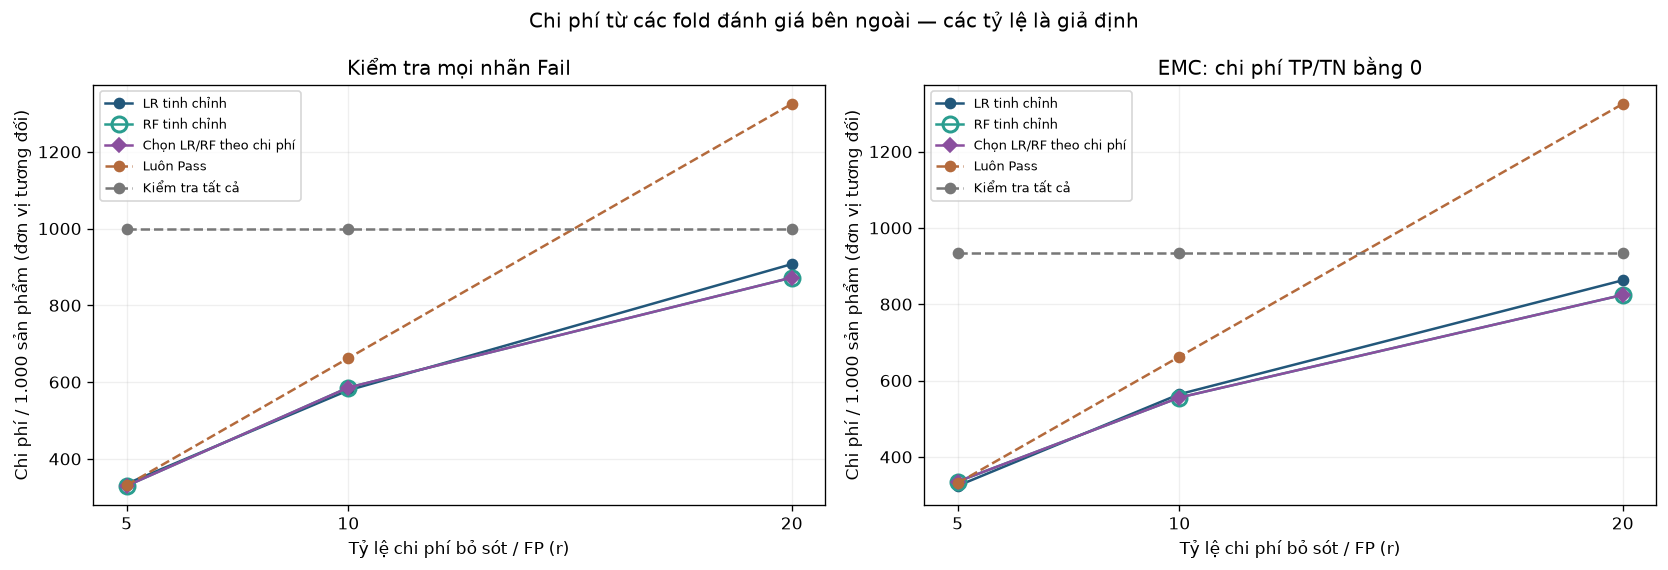

In [9]:
scope_labels = {
    "LR": "LR tinh chỉnh", "RF": "RF tinh chỉnh",
    "cost_selected": "Chọn LR/RF theo chi phí",
    "always_pass": "Luôn Pass", "review_all": "Kiểm tra tất cả",
}
scope_colors = {
    "LR": "#22577A", "RF": "#2A9D8F", "cost_selected": "#8A4F9E",
    "always_pass": "#B46A3C", "review_all": "#777777",
}
family_labels = {
    "review_all_alerts": "Kiểm tra mọi nhãn Fail",
    "misclassification": "EMC: chi phí TP/TN bằng 0",
}
families = list(summary["cost_family"].drop_duplicates())

fig, axes = plt.subplots(1, len(families), figsize=(7 * len(families), 4.8), squeeze=False)
for ax, cost_family in zip(axes[0], families):
    family_rows = summary[summary["cost_family"].eq(cost_family)]
    for scope in scope_labels:
        points = family_rows[family_rows["selection_scope"].eq(scope)].sort_values("cost_ratio")
        if points.empty:
            continue
        ax.plot(
            points["cost_ratio"], points["cost_per_1000"],
            marker="D" if scope == "cost_selected" else "o",
            markersize=9 if scope == "RF" else 6,
            markerfacecolor="none" if scope == "RF" else scope_colors[scope],
            markeredgewidth=1.8 if scope == "RF" else 1.0,
            color=scope_colors[scope], label=scope_labels[scope],
            linestyle="--" if scope in {"always_pass", "review_all"} else "-",
        )
    ax.set(title=family_labels[cost_family], xlabel="Tỷ lệ chi phí bỏ sót / FP (r)",
           ylabel="Chi phí / 1.000 sản phẩm (đơn vị tương đối)")
    ax.set_xticks(cost_ratios)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.suptitle("Chi phí từ các fold đánh giá bên ngoài — các tỷ lệ là giả định", fontsize=12)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "nested_cost_sensitivity.png", dpi=170, bbox_inches="tight")
plt.show()

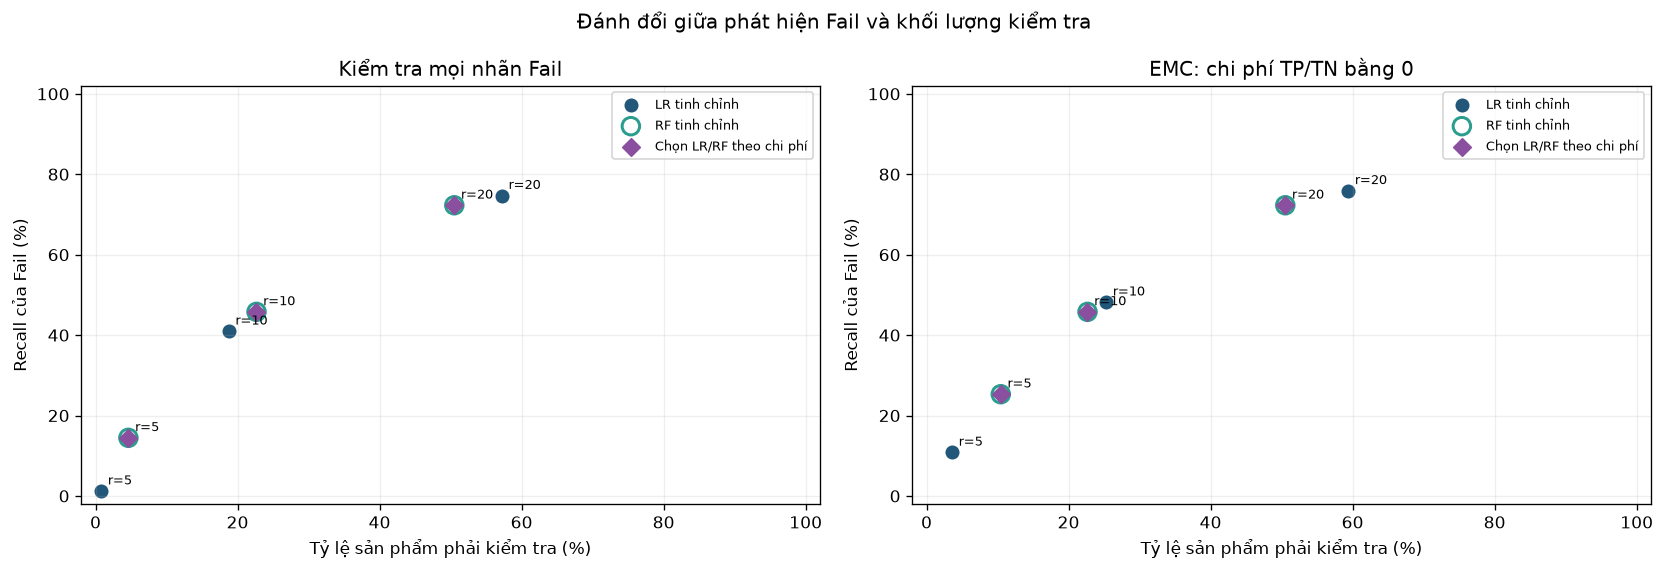

In [10]:
fig, axes = plt.subplots(1, len(families), figsize=(7 * len(families), 4.8), squeeze=False)
for ax, cost_family in zip(axes[0], families):
    family_rows = summary[summary["cost_family"].eq(cost_family)]
    seen_annotations = set()
    for scope in ["LR", "RF", "cost_selected"]:
        points = family_rows[family_rows["selection_scope"].eq(scope)].sort_values("cost_ratio")
        ax.scatter(
            100 * points["inspection_rate"], 100 * points["recall"],
            s=110 if scope == "RF" else 55,
            marker="D" if scope == "cost_selected" else "o",
            facecolors="none" if scope == "RF" else scope_colors[scope],
            edgecolors=scope_colors[scope], linewidths=1.8 if scope == "RF" else 1.0,
            label=scope_labels[scope],
        )
        for point in points.itertuples(index=False):
            annotation_key = (point.inspection_rate, point.recall, point.cost_ratio)
            if annotation_key in seen_annotations:
                continue
            seen_annotations.add(annotation_key)
            ax.annotate(
                f"r={point.cost_ratio:g}",
                (100 * point.inspection_rate, 100 * point.recall),
                xytext=(4, 4), textcoords="offset points", fontsize=8,
            )
    ax.set(title=family_labels[cost_family], xlabel="Tỷ lệ sản phẩm phải kiểm tra (%)",
           ylabel="Recall của Fail (%)", xlim=(-2, 102), ylim=(-2, 102))
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.suptitle("Đánh đổi giữa phát hiện Fail và khối lượng kiểm tra", fontsize=12)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "nested_recall_vs_inspections.png", dpi=170, bbox_inches="tight")
plt.show()

## 10. Chọn cấu hình cuối cho từng kịch bản và lưu riêng

Sau khi đánh giá quy trình bằng nested CV, tạo OOF 5-fold trên toàn bộ train để chọn cấu hình/ngưỡng cho từng kịch bản, rồi fit các mô hình cần dùng trên toàn bộ train. Các chi phí OOF ở bước này là **điểm dùng để chọn**, có thể lạc quan; không thay cho số đo vòng ngoài ở mục 9.

Không có một mô hình cuối duy nhất cho doanh nghiệp khi chưa chốt ma trận chi phí. Các policy được lưu riêng để có thể đối chiếu; dashboard và artifact hiện tại của notebook 03 không bị thay đổi.

In [11]:
final_start = time.perf_counter()
final_results = fit_final_cost_policies(
    X_train, y_train, candidates, scenarios,
    cv_splits=FINAL_SPLITS, seed=SEED, verbose=True,
)
final_seconds = time.perf_counter() - final_start
final_policies = final_results["policies"].copy()
assert final_policies["estimate_type"].eq("selection_only_not_unbiased").all()

metadata = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "experiment": "cost_sensitive_classification_assumed_costs",
    "seed": int(SEED),
    "outer_splits": OUTER_SPLITS,
    "inner_splits": INNER_SPLITS,
    "final_selection_splits": FINAL_SPLITS,
    "n_train": int(len(y_train)),
    "n_train_fail": int(y_train.sum()),
    "n_features_raw": int(X_train.shape[1]),
    "n_holdout_excluded": int(len(holdout_idx)),
    "holdout_evaluated": False,
    "timestamp_used_as_feature": False,
    "costs_are_assumptions": True,
    "cost_unit": "relative_unit_not_currency",
    "company_costs_available": False,
    "review_assumption": "Every predicted Fail is reviewed; review detects the defect.",
    "miss_cost_assumption": "Expected remaining cost of a missed Fail at this decision step.",
    "minimum_recall_constraint": None,
    "baseline_results_status": "Previously measured results, not hypothetical values.",
    "nested_runtime_seconds": float(nested_seconds),
    "final_selection_runtime_seconds": float(final_seconds),
    "python_version": sys.version,
    "package_versions": {
        name: version(name)
        for name in ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "joblib"]
    },
    "candidate_grid": [
        {"candidate_id": candidate.candidate_id, "family": candidate.family,
         "params": candidate.params}
        for candidate in candidates
    ],
    "cost_scenarios": [asdict(scenario) for scenario in scenarios],
}

config_path = save_final_cost_policies(final_results, OUTPUT_DIR, scenarios, metadata=metadata)
(OUTPUT_DIR / "run_metadata.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8"
)
assert Path(config_path).is_file()

policy_display_columns = [
    "scenario", "selection_scope", "selected_family", "selected_candidate", "threshold",
    "cost_per_1000", "precision", "recall", "n_inspections", "fp", "fn", "estimate_type",
]
display(final_policies[policy_display_columns].round(5))
print("Policy config riêng:", config_path)
print(f"Thời gian chọn và fit cuối: {final_seconds:.1f} giây.")
print("Không thay đổi mô hình/ngưỡng đang dùng trong dashboard.")

  OOF candidates 1/21


  OOF candidates 5/21


  OOF candidates 10/21


  OOF candidates 15/21


  OOF candidates 20/21


  OOF candidates 21/21


,scenario,selection_scope,selected_family,selected_candidate,threshold,cost_per_1000,precision,recall,n_inspections,fp,fn,estimate_type
0,review_r5,LR,LR,lr_k40_c1,0.84185,319.23384,0.23750,0.22892,80,61,64,selection_only_not_unbiased
1,review_r5,RF,RF,rf_k40_dNone_leaf5,0.58533,311.25299,0.36667,0.13253,30,19,72,selection_only_not_unbiased
2,review_r5,cost_selected,RF,rf_k40_dNone_leaf5,0.58533,311.25299,0.36667,0.13253,30,19,72,selection_only_not_unbiased
3,review_r10,LR,LR,lr_k40_c10,0.62384,560.25539,0.15766,0.42169,222,187,48,selection_only_not_unbiased
4,review_r10,RF,RF,rf_k80_dNone_leaf5,0.34429,525.13966,0.19149,0.43373,188,152,47,selection_only_not_unbiased
5,review_r10,cost_selected,RF,rf_k80_dNone_leaf5,0.34429,525.13966,0.19149,0.43373,188,152,47,selection_only_not_unbiased
6,review_r20,LR,LR,lr_k20_c10,0.39204,825.21947,0.11089,0.68675,514,457,26,selection_only_not_unbiased
7,review_r20,RF,RF,rf_k80_dNone_leaf5,0.16727,719.87231,0.10399,0.87952,702,629,10,selection_only_not_unbiased
8,review_r20,cost_selected,RF,rf_k80_dNone_leaf5,0.16727,719.87231,0.10399,0.87952,702,629,10,selection_only_not_unbiased
9,emc_r5,LR,LR,lr_k40_c1,0.84185,304.07023,0.23750,0.22892,80,61,64,selection_only_not_unbiased


Policy config riêng: D:\AI_Bussiness_Huflit\Đồ án cuối\artifacts\cost_sensitive\policy_configs.json
Thời gian chọn và fit cuối: 27.2 giây.
Không thay đổi mô hình/ngưỡng đang dùng trong dashboard.


## 11. Kết luận từ số đo, không từ giả định ngầm

Các nhận xét dưới đây lấy từ **nested CV**, không lấy điểm OOF dùng để chọn cuối. Chi phí được báo bằng đơn vị tương đối trên mỗi 1.000 sản phẩm, với tỷ lệ lớp của dữ liệu train. Nếu tỷ lệ Fail khi vận hành khác dữ liệu này, cần đánh giá lại chi phí với phân bố phù hợp.

Một phương án có thể tốt ở r=5 và kém ở r=20. BER thấp hơn không tự đảm bảo chi phí thấp hơn; Precision cao cũng không đủ nếu bỏ sót nhiều Fail. Chỉ chốt policy doanh nghiệp sau khi có chi phí và/hoặc giới hạn kiểm tra, mức phát hiện lỗi tối thiểu.

In [12]:
for scenario in scenarios:
    if scenario.family != "review_all_alerts":
        continue
    rows = summary[summary["scenario"].eq(scenario.name)].set_index("selection_scope")
    chosen_procedure = rows.loc["cost_selected"]
    always_pass = rows.loc["always_pass"]
    review_all = rows.loc["review_all"]
    ml_rows = rows.loc[["LR", "RF", "cost_selected"]]
    observed_best_scope = ml_rows["cost_per_product"].idxmin()
    print(f"\n{scenario.name}: một lần kiểm tra = 1; bỏ sót một Fail = {scenario.fn_cost:g}.")
    print(
        "  Quy trình chọn theo chi phí: "
        f"{chosen_procedure.cost_per_1000:.2f} đơn vị/1.000 sản phẩm; "
        f"Recall={chosen_procedure.recall:.3f}; "
        f"kiểm tra {int(chosen_procedure.n_inspections)}/{int(chosen_procedure.n_samples)}; "
        f"bỏ sót {int(chosen_procedure.fn)}/{int(chosen_procedure.tp + chosen_procedure.fn)} Fail."
    )
    print(
        f"  Mốc luôn Pass: {always_pass.cost_per_1000:.2f}; "
        f"kiểm tra tất cả: {review_all.cost_per_1000:.2f} đơn vị/1.000 sản phẩm."
    )
    print(f"  Chi phí quan sát thấp nhất trong ba quy trình ML ở vòng ngoài: {observed_best_scope}.")

print("\nKhông suy ra một ngưỡng tối ưu doanh nghiệp duy nhất khi chưa có chi phí thực tế.")
print("Không quy đổi thành tiền, không khẳng định tiết kiệm thực tế hoặc sẵn sàng triển khai.")
print("Các policy cuối được chọn từ OOF-train; điểm đánh giá quy trình lấy từ nested CV.")


review_r5: một lần kiểm tra = 1; bỏ sót một Fail = 5.
  Quy trình chọn theo chi phí: 329.61 đơn vị/1.000 sản phẩm; Recall=0.145; kiểm tra 58/1253; bỏ sót 71/83 Fail.
  Mốc luôn Pass: 331.21; kiểm tra tất cả: 1000.00 đơn vị/1.000 sản phẩm.
  Chi phí quan sát thấp nhất trong ba quy trình ML ở vòng ngoài: RF.

review_r10: một lần kiểm tra = 1; bỏ sót một Fail = 10.
  Quy trình chọn theo chi phí: 585.79 đơn vị/1.000 sản phẩm; Recall=0.458; kiểm tra 284/1253; bỏ sót 45/83 Fail.
  Mốc luôn Pass: 662.41; kiểm tra tất cả: 1000.00 đơn vị/1.000 sản phẩm.
  Chi phí quan sát thấp nhất trong ba quy trình ML ở vòng ngoài: LR.

review_r20: một lần kiểm tra = 1; bỏ sót một Fail = 20.
  Quy trình chọn theo chi phí: 872.31 đơn vị/1.000 sản phẩm; Recall=0.723; kiểm tra 633/1253; bỏ sót 23/83 Fail.
  Mốc luôn Pass: 1324.82; kiểm tra tất cả: 1000.00 đơn vị/1.000 sản phẩm.
  Chi phí quan sát thấp nhất trong ba quy trình ML ở vòng ngoài: RF.

Không suy ra một ngưỡng tối ưu doanh nghiệp duy nhất khi chưa có 

## Tệp kết quả và cách dùng lại

- `artifacts/cost_sensitive/cost_scenarios.csv`: ma trận chi phí và nhãn giả định.
- `candidate_grid.csv`: các cấu hình đã thử.
- `nested_summary.csv`: chi phí và các chỉ số tổng hợp từ fold đánh giá ngoài.
- `nested_fold_metrics.csv`, `nested_outer_predictions.csv`, `nested_inner_search.csv`: dữ liệu kiểm tra từng bước và số đo từng fold.
- `policy_configs.json`, các bảng chọn cuối và thư mục `models/`: policy theo từng kịch bản; **chưa tự thay thế baseline**.
- `run_metadata.json`: cách chia dữ liệu, phiên bản thư viện, giả định và cấu hình chạy.
- `figures/cost_sensitive/`: đồ thị chi phí theo tỷ lệ và Recall theo khối lượng kiểm tra.

Khi sử dụng một policy, phải dùng đúng pipeline, thứ tự 590 cột và ngưỡng của policy đó; không dùng thêm preprocessing bên ngoài. Không lấy công thức ngưỡng từ tỷ lệ chi phí rồi áp thẳng vào score chưa được xác nhận calibration. Nếu cần kết luận triển khai, cần dữ liệu xác nhận mới và chi phí doanh nghiệp.

Notebook d?ng module tr? gi?p `secom_cost_sensitive.py` ? th? m?c g?c; gi? file n?y c?ng d? ?n khi ch?y l?i.